# Biological Oceanography - Week 7 Practical (Primary Production)

## Overview of the Practical

In this practical, we will learn how to estimate primary production in the ocean using an available-light model of photosynthesis, by making some assumptions on the parameters of the photosynthesis irradiance equation, and using two input variables that can be derived from satellite ocean-colour data: the chlorophyll-a concentration (a measure of phytoplankton biomass, denoted $B$) and photosynthetically available radiation (PAR). This practical builds on your lecture on primary production, showing how we can use satellite data together with simple models to estimate primary production over wide areas. 

This practical is based on a notebook originally written by Bob Brewin (University of Exeter) and modified by Noam Vogt-Vincent and Heather Bouman.

## Technical instructions

Please note that this practical is designed such that each cell (block of Python code) is run after the previous cell. If you clear or restart the practical, you will need to run through each cell from the start. If you are running this practical through binder, please be aware that the memory can sometimes get randomly cleared, resulting in error messages claiming variables do not exist. If this occurs, you just need to rerun the cells again (e.g. `Run > Run All Cells`). If you are using binder, please also note that your session **will not be saved**! If you want to save your notebook and/or figures for future use, you will need to make an offline copy (`File > Save Notebook As`).

Please run the following lines of code to ensure you have the right packages installed for the practical. To do this click on the code (cell) below and then click the run button at the top of the page.

In [1]:
#Import all packages required for practical
import numpy as np
import math as mt
import array as arr 
import scipy.integrate as spi
import matplotlib as mpl
from matplotlib import pyplot as plt 
from matplotlib import ticker as cm
from matplotlib.colors import LogNorm  
from netCDF4 import Dataset
#Cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from mpl_toolkits.axes_grid1 import make_axes_locatable

## Definition of primary production

Primary production is defined as the conversion of inorganic carbon (in the form of carbon dioxide) into organic carbon using light as the energy source. In the ocean it is expressed either in terms of mass of carbon fixed per unit volume of water per unit time, or vertically integrated across the water column to give mass of carbon fixed per unit surface area of ocean. 


## Simple models of primary production
### Biomass-normalised primary production

In computing primary production ($P$) it is common to work with the biomass-normalised primary production variable ($P^B$), where $B$ refer to the biomass of phytoplankton which in this exercise we take to be the chlorophyll-a concentration, such that 

\begin{equation}
P = B \times P^B,
\end{equation}

and 

\begin{equation}
P^B = \frac{P}B.
\end{equation}


By doing this, we can focus our efforts on modelling $P^B$, and use $B$ to scale between $P^B$ and $P$. This is useful in the context of satellite remote sensing as fields of $B$ are available through satellite ocean colour. 

Let us start with a very simple example. 

Hypothetically, let say we went out on a research ship and measured $P^B$ at a location in the North Atlantic to be 3 (mg C (mg $B$)$^{−1}$ h$^{-1}$). At the same location, on the same day, a satellite estimated $B$ (mg m$^{-3}$) at 9 pixels (pixel size 1 km, covering an area of 3 $\times$ 3 km, 9 km$^2$) surrounding the location of the ship. Let’s compute primary production for each of the nine pixels in the area around the ship.

Run the following lines of Python code for the example.

In [2]:
# Biomass of phytoplankton (Chlorophyll-a concentration) for 9 pixels surrounding the ship
B = np.array([0.5,0.6,0.8,0.9,1.2,1.4,0.8,0.7,1.0]).reshape(3,3)

# Create an array the same shape as B, filled with biomass-normalised primary production
PB = np.full(B.shape, 3.0)

# Compute primary production at each of the 9 pixels
P = PB * B

# Print results to 1 decimal place
print(np.array2string(P, formatter={'float_kind': lambda x: f'{x:.1f}'}))

[[1.5 1.8 2.4]
 [2.7 3.6 4.2]
 [2.4 2.1 3.0]]


Having computed primary production for the nine pixels we can average and compute the standard deviation of the region surrounding the ship. Run the following lines of Python code.

In [3]:
#Compute mean of 9 pixels
P_av = np.mean(P)

#Compute standard deviation of 9 pixels
P_sd = np.std(P)

# Print results
print(f'Mean = {P_av:.1f} mg C/m³/h')
print(f'Standard deviation = {P_sd:.1f} mg C/m³/h')

Mean = 2.6 mg C/m³/h
Standard deviation = 0.8 mg C/m³/h


The average primary production surrounding the ship is therefore 2.6 (mg C m$^{-3}$ h$^{-1}$) with a standard deviation of 0.8 (mg C m$^{-3}$ h$^{-1}$).

**Question:** How would we measure $P^B$ in the first place? What does this value depend on and how variable is it in space and time?

### Available-light models of biomass-normalised primary production

The biomass-normalised primary production can be expressed using an available light model (Platt et al. 1980), such that

\begin{equation}
P^B = P^B_m \left(1-\exp\left(-\frac{\alpha^B I}{P^B_m}\right)\right) = P^B_m \left(1-\exp\left(-\frac{I}{I_k}\right)\right),
\end{equation}

where $P^B_m$ is the assimilation number of the light-saturation curve (maximum photosynthetic rate normalised by biomass in the absence of photoinhibition), $\alpha^B$ is the initial slope, $I$ is the total available irradiance (which we take to be the photosynthetically available radiation, PAR), and $I_k=P^B_m/\alpha^B$ is the light saturation index. For simplicity, we have not included the effect of photoinhibition, which can occur in nature (Platt et al. 1980).

Let us see how this equation looks graphically using python. Run the following lines of Python code.

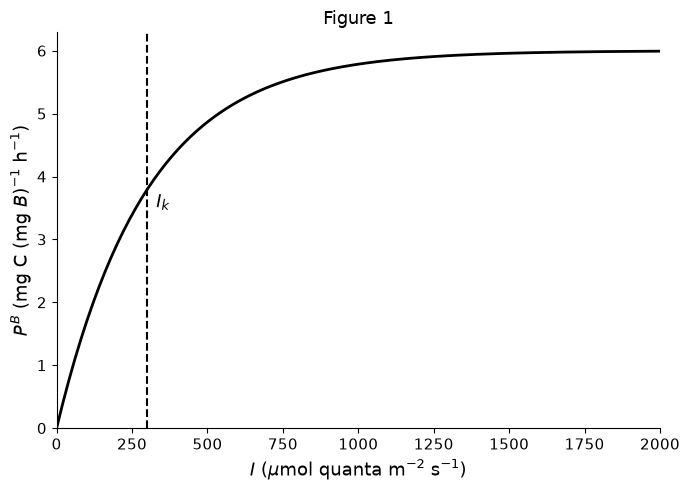

In [4]:
# Define parameters
PB_M = 6.0
A_B = 0.02

# Create an array of light values (μmol quanta m⁻² s⁻¹)
I = np.linspace(0, 2000, 200)

# Compute biomass-normalised primary production
PB = PB_M * (1 - np.exp(-(A_B / PB_M) * I))

# Compute saturation irradiance
I_k = PB_M / A_B

# Create figure
fig, ax = plt.subplots(figsize=(7, 5))

# Plot as a solid black line
ax.plot(I, PB, color='black', linewidth=2)

# Plot saturation irradiance as a vertical dashed line
ax.axvline(I_k, color='black', linestyle='--', linewidth=1.5)
ax.text(I_k + 30, 3.5, r'$I_k$', fontsize=13)

# Axis labels
ax.set_xlabel(r'$I$ ($\mu$mol quanta m$^{-2}$ s$^{-1}$)', fontsize=13)
ax.set_ylabel(r'$P^B$ (mg C (mg $B$)$^{-1}$ h$^{-1}$)', fontsize=13)

# Axis limits
ax.set_xlim(0, 2000)
ax.set_ylim(0, None)

# Remove top and right axes
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Format ticks
ax.tick_params(axis='both', direction='out', labelsize=11)

# Remove grid and adjust layout
ax.grid(False)
ax.set_title('Figure 1', fontsize=13)
plt.tight_layout()

plt.show()

This classical relationship (Webb et al. 1974) lies at the heart of models of ocean primary production, although note that the exact parameterisation varies between studies (e.g. a $\tanh$ function is often used instead).

**Question:** What does the parameter $I_k$ represent ecologically?

In this example, we assume $P^B_m$ = 6.0 (mg C (mg Chl-a)$^{-1}$ h$^{-1}$) and $\alpha^B$ = 0.02 (mg C (mg Chl-a)$^{-1}$ h$^{-1}$ ($\mu$mol quanta m$^{-2}$ s$^{-1}$)$^{-1}$). In the natural environment, $P^B_m$ typically ranges between 0.2 to 25 mg C (mg Chl-a)$^{-1}$ h$^{-1}$ and $\alpha^B$ 0.005 to 0.2. In the code above, change values for these parameters (named as PB_M for $P^B_m$ and A_B for $\alpha^B$), re-run the code and see how the figure changes.

### Assumptions of our model of primary production

In the above sections, we have introduced all the key components required to compute primary production: the chlorophyll-a concentration ($B$), light ($I$), and the assimilation number ($P^B_m$) and initial slope ($\alpha^B$) of the light-saturation curve (Figure 1). However, these components are not static, but vary in time and depth, and with wavelength in the case of $I$ and $\alpha^B$.

For the sake of simplicity, in this practical we make the following assumptions:

- We deal with total light (PAR), without taking into account spectral variations in light or the spectral selectivity in absorption and utilisation of light for photosynthesis.
- The chlorophyll-a concentration ($B$), the assimilation number ($P^B_m$) and inital slope ($\alpha^B$) remains constant over the period of one day.
- The chlorophyll-a concentration ($B$), the assimilation number ($P^B_m$) and inital slope ($\alpha^B$) are constant with depth. This follows the case of a vertically homogeneous water column (no deep chlorophyll-a maximum, i.e. assuming that the vertical mixing timescale is much shorter than phytoplankton population or photoacclimation dynamics), and assumes phytoplankton are adapted to the average light conditions in the sun-lit region of the ocean).

In reality, there are clear cases where these assumptions do not hold. However, there are situations where it is reasonable to make these assumptions. One important factor to consider however, when modelling primary production, is variations in light with time ($t$) over the day period, and depth ($z$).

Following our asummptions, we can express primary production as

\begin{equation}
\begin{gathered}
P(z,t) = B P^B_m \left[1 - \exp\left(-\frac{I(z,t)}{I_k}\right)\right],\\
I_k = \frac{P^B_m}{\alpha^B}.
\end{gathered}
\end{equation}


To solve this equation, we need estimates of $I(z,t)$.

### Variations in light with depth and time

Photosynthetically available radiation (PAR) is a standard product produced by space agencies (see https://modis.gsfc.nasa.gov/data/dataprod/par.php). It represents total available irradiance from 400 to 700 nanometers just above the water surface. This value is typically provided by space agencies in Einstein m$^{-2}$ d$^{-1}$, representing integrated irradiance over the daylength ($D$). To go from PAR to $I(z,t)$, we first convert PAR from Einstein m$^{-2}$ d$^{-1}$ into $\mu$mol m$^{-2}$ d$^{-1}$.

We then estimate the surface maximum irradiance just above the water surface ($I_m(0^+)$) at mid-day. Assuming $I(0^+,t)=I_m(0^+)\sin{\left(\pi\ t/D\right)}$, where $D$ is expressed in seconds, the integrated irradiance over the daylength (PAR) is given by

\begin{equation}
\mathrm{PAR} = \int_0^D I(0^+,t)\ dt = \frac{2D}{\pi}I_m(0^+),
\end{equation}

and therefore

\begin{equation}
I_m(0^+) = \frac{\pi}{2D}\mathrm{PAR}.
\end{equation}

**Question**: How accurate do you think this estimate of $I_m(0^+)$ will be (assuming the PAR figures have no uncertainty associated with them)?

To account for the transmission of light at the air-sea water interface, we subtract 2% (reflected light) from $I_m(0^+)$ to get from above to below water ($I_m(0^-)$), i.e.  $I_m(0^-)=I_m(0^+)T_{as}$ where $T_{as}=0.98$ is the transmittance across the air-sea interface. This number (0.98) is relatively constant for sun-zenith angles from 0 to 40$^{\circ}$, typically observed at local noon in the tropics, but decreases with sun-zenith angle and is also reduced by wind speed (which increases surface roughness).

Having derived $I_m(0^-)$, the values of irradiance $I(0^-,t)$ during the day, just below the air-sea interface, can then be computed according to

\begin{equation}
I(0^-,t) = I_m(0^+)T_{as} \sin\left(\frac{\pi t}{D}\right),
\end{equation}

where daylight begins at $t=0$ and ends at $t=D$. Variations in $I$ with depth ($z$) are modelled according to the Beer-Lambert Law, such that

\begin{equation}
I(z,t) = I_m(0^+)T_{as} \sin\left(\frac{\pi t}{D}\right)\exp\left[{-K_dz}\right],
\end{equation}

where $K_d$ is the diffuse attenuation coefficient for PAR (m$^{-1}$). The value of $K_d$ is dependent on the optical properties of the water, and is a product provided as standard by space agencies and covaries with $B$ in open-ocean waters. In cases of a non-uniform profile of phytoplankton, $K_d$ will vary with depth. But following our assumption of a homogeneous water column, in this practical, we can make the assumption of a constant $K_d$ (as we did with $B$).

**Question:** Why might open-ocean relationships between $K_d$ and $B$ differ in coastal waters?

Putting all this together, we have the following equations that we want to solve:

\begin{equation}
\begin{gathered}
P(z,t) = B P^B_m \left[1 - \exp\left(-\frac{I(z,t)}{I_k}\right)\right],\\
I(z,t) = I_m(0^+)T_{as} \sin\left(\frac{\pi t}{D}\right)\exp\left[{-K_dz}\right],\\
I_k = \frac{P^B_m}{\alpha^B}.
\end{gathered}
\end{equation}

Let us see how these equations looks graphically using python. The following code calculates $I(z,t)$ given latitude, the day of year, and $K_d$. Why do latitude and day of year affect $I(z,t)$?

Latitude: 40.0° | Day of year: 140
Daylength = 14.4 hours
PAR = 59.4 Einstein m⁻² d⁻¹
Maximum surface irradiance = 1767.9 μmol m⁻² s⁻¹


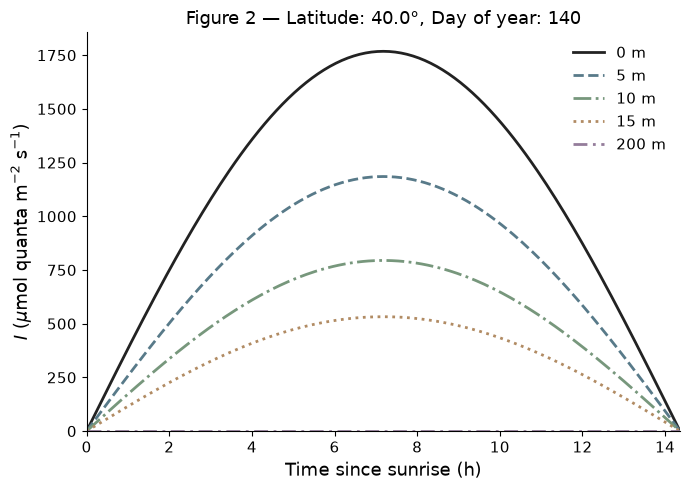

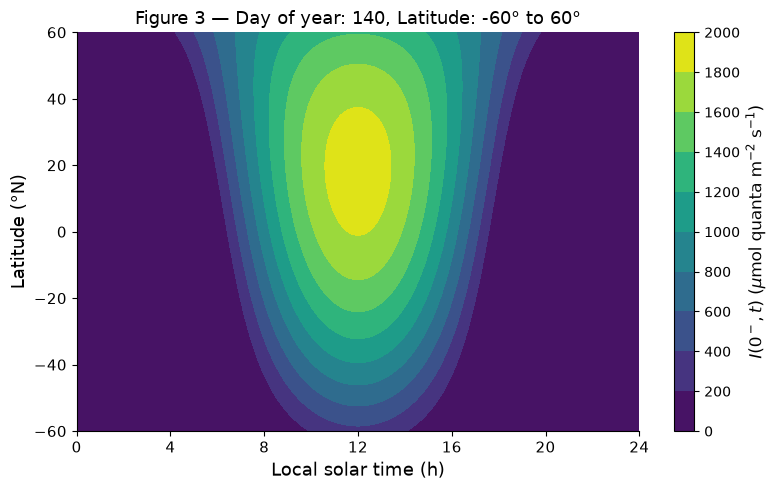

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# --------------------------------------------------
# Define parameters
# --------------------------------------------------

Latitude = 40.0
dayOfYear = 140
Kd = 0.08                # m^-1

Tas = 0.98               # Air-sea transmittance
Tatm = 0.70              # Atmospheric transmission

MaxDepth = 200.0         # Maximum depth plotted (m)

# --------------------------------------------------
# Define solar geometry and PAR functions
# --------------------------------------------------

def solar_geometry(latitude, dayOfYear):

    # Convert latitude to radians
    phi = np.deg2rad(latitude)

    # Solar declination (radians)
    solar_declination = np.deg2rad(23.44) * np.sin(
        2 * np.pi * (dayOfYear - 81) / 365
    )

    # Sunrise/sunset hour angle
    cos_H0 = -np.tan(phi) * np.tan(solar_declination)
    H0 = np.arccos(np.clip(cos_H0, -1, 1))

    return phi, solar_declination, H0


def calculate_daylength(latitude, dayOfYear):

    # Calculate sunrise/sunset hour angle
    phi, solar_declination, H0 = solar_geometry(
        latitude, dayOfYear
    )

    # Daylength in seconds
    D = 86400 * H0 / np.pi

    return D


def calculate_PAR(latitude, dayOfYear, Tatm=0.70):

    # Constants
    S0 = 1361.0           # Solar constant (W m^-2)
    fPAR = 0.45           # Fraction of solar radiation in PAR
    E_PAR = 2.18e5        # Energy per mole of PAR photons (J mol^-1)

    # Calculate solar geometry
    phi, solar_declination, H0 = solar_geometry(
        latitude, dayOfYear
    )

    # Daily mean extraterrestrial solar irradiance
    Q0 = (S0 / np.pi) * (
        H0 * np.sin(phi) * np.sin(solar_declination)
        + np.cos(phi) * np.cos(solar_declination) * np.sin(H0)
    )

    # Daily integrated surface PAR (Einstein m^-2 d^-1)
    PAR = Q0 * 86400 * fPAR * Tatm / E_PAR

    return PAR


# --------------------------------------------------
# Calculate daylength and irradiance
# --------------------------------------------------

# Daylength (seconds)
D = calculate_daylength(Latitude, dayOfYear)

# Daily integrated PAR (Einstein m^-2 d^-1)
PAR = calculate_PAR(Latitude, dayOfYear, Tatm)

# Convert PAR to micromoles
PAR = PAR * 1e6

# Maximum surface irradiance above and below water
Im_pl = np.pi * PAR / (2 * D)
Im_mn = Im_pl * Tas

# Time and depth arrays
Time = np.linspace(0, D, 201)
Depth = np.linspace(0, MaxDepth, 201)

# Vectorised calculation of irradiance
I = (
    Im_mn
    * np.sin(np.pi * Time[:, None] / D)
    * np.exp(-Kd * Depth[None, :])
)

# Print calculated parameters
print(f'Latitude: {Latitude:.1f}° | Day of year: {dayOfYear}')
print(f'Daylength = {D / 3600:.1f} hours')
print(f'PAR = {PAR / 1e6:.1f} Einstein m⁻² d⁻¹')
print(f'Maximum surface irradiance = {Im_mn:.1f} μmol m⁻² s⁻¹')


# --------------------------------------------------
# Figure 2: Irradiance through the day
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 5))

# Depths to display
PlotDepths = [0, 5, 10, 15, MaxDepth]

# Muted colours and different line styles
colors = ['#222222', '#587A89', '#77977C',
          '#B18B63', '#947C9B']
styles = ['-', '--', '-.', ':', (0, (5, 2, 1, 2))]

for depth, color, style in zip(PlotDepths, colors, styles):

    # Calculate irradiance at selected depth
    I_depth = (
        Im_mn
        * np.sin(np.pi * Time / D)
        * np.exp(-Kd * depth)
    )

    ax.plot(
        Time / 3600,
        I_depth,
        color=color,
        linestyle=style,
        linewidth=2,
        label=f'{depth:g} m'
    )

# Axis labels
ax.set_xlabel('Time since sunrise (h)', fontsize=13)
ax.set_ylabel(
    r'$I$ ($\mu$mol quanta m$^{-2}$ s$^{-1}$)',
    fontsize=13
)

# Axis limits
ax.set_xlim(0, D / 3600)
ax.set_ylim(0, None)

# Plot title
ax.set_title(
    f'Figure 2 — Latitude: {Latitude:.1f}°, Day of year: {dayOfYear}',
    fontsize=13
)
# Legend
ax.legend(frameon=False, fontsize=11)

# Remove top and right axes
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Format ticks
ax.tick_params(axis='both', direction='out', labelsize=11)

ax.grid(False)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Figure 3: Irradiance vs time of day and latitude
# --------------------------------------------------

# Latitude and local solar time arrays
Latitudes = np.linspace(-60, 60, 241)
Hours = np.linspace(0, 24, 481)

# Daylength at each latitude (hours)
D_lat = calculate_daylength(Latitudes, dayOfYear) / 3600

# Daily integrated PAR at each latitude
PAR_lat = calculate_PAR(Latitudes, dayOfYear, Tatm) * 1e6

# Sunrise and sunset, centred on local noon
Sunrise = 12 - D_lat / 2
Sunset = 12 + D_lat / 2

# Maximum surface irradiance at each latitude
Im_lat = np.pi * PAR_lat * Tas / (2 * D_lat * 3600)

# Calculate time since sunrise at each latitude
Time_since_sunrise = Hours[None, :] - Sunrise[:, None]

# Fraction of daylight elapsed
Day_fraction = Time_since_sunrise / D_lat[:, None]

# Calculate irradiance using the sinusoidal model
I_lat_time = (
    Im_lat[:, None]
    * np.sin(np.pi * Day_fraction)
)

# Set irradiance to zero outside daylight hours
Daylight = (
    (Hours[None, :] >= Sunrise[:, None])
    & (Hours[None, :] <= Sunset[:, None])
)

I_lat_time = np.where(Daylight, I_lat_time, 0.0)

# Use linear irradiance scaling, including zero
I_plot = np.maximum(I_lat_time, 0.0)


# --------------------------------------------------
# Plot Figure 3
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

# Rounded colour levels
levels = MaxNLocator(nbins=10).tick_values(0, np.max(I_plot))

# Create contour plot
contour = ax.contourf(
    Hours,
    Latitudes,
    I_plot,
    levels=levels,
    cmap='viridis'
)

# Colour bar with rounded tick values
cbar = fig.colorbar(contour, ax=ax, ticks=levels)
cbar.set_label(
    r'$I(0^-,t)$ ($\mu$mol quanta m$^{-2}$ s$^{-1}$)',
    fontsize=12
)

# Axis labels
ax.set_xlabel('Local solar time (h)', fontsize=13)
ax.set_ylabel('Latitude (°N)', fontsize=13)

# Axis limits
ax.set_xlim(0, 24)
ax.set_ylim(-60, 60)
ax.set_xticks(np.arange(0, 25, 4))

# Plot title
ax.set_title(
    f'Figure 3 — Day of year: {dayOfYear}, Latitude: {Latitudes.min():.0f}° to {Latitudes.max():.0f}°',
    fontsize=13
)
# Remove top and right axes
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Format ticks
ax.tick_params(axis='both', direction='out', labelsize=11)

ax.grid(False)
plt.tight_layout()
plt.show()

As you can see in Figure 2 and 3, we have now computed the light environment ($I$) for different times ($t$) of the day (minimum dawn and dusk, maximum at noon), and for a variety of depths ($z$, Figure 2 only). Have a play with different inputs (changing latitude, day of year, and Kd at the top of the code above) and re-run the code. For a realistic range, values typically vary in the open ocean between:

- `Latitude` (-90 to 90)
- `dayOfYear` (1 to 366)
- `Kd` (0.02 to 0.2)    

Note how the light environment is controlled by where you are (latitude) on Earth, the time of year (season), and how light attenuates with depth ($K_d$). Also worth noting that this simple approach (sinusoidal light cycle) is more appropriate for lower latitudes (not for polar regions).

### Computation of primary production 

Having computed our light environment, we are now in a position to compute primary production at a specific time ($t$) and depth ($z$), as shown in the previous equation, and shown again here for clarity

\begin{equation}
\begin{gathered}
P(z,t) = B P^B_m \left[1 - \exp\left(-\frac{I(z,t)}{I_k}\right)\right],\\
I(z,t) = I_m(0^+)T_{as} \sin\left(\frac{\pi t}{D}\right)\exp\left[{-K_dz}\right],\\
I_k = \frac{P^B_m}{\alpha^B}.
\end{gathered}
\end{equation}

Let us use these equation in python and look graphically at the output. Before we do this, and to keep our simulations realistic, we will empirically relate $K_d$ to $B$ using the equation of Morel et al. (2007). This follow the classical Case 1 assumption that in the open ocean, the optical properties of the water are controlled by phytoplankton and their covarying material (detrital and dissolved substances). Note there are satellite algorithms that estimate $B$ and $K_d$ independently, but for the sake of consistency in our model, we will tie these two variables to avoid unrealistic simulations (e.g. where $B$ is high but $K_d$ low). Following Morel et al. (2007) we can approximate $K_d$ according to

\begin{equation}
K_d = \frac{4.6}{10^{[q_a + q_b\log_{10}(B) + q_c\log_{10}(B)^2 + q_d\log_{10}(B)^3]}},
\end{equation}

where $q_a = 1.524$, $q_b = -0.436$ , $q_c = -0.0145$ and $q_d = 0.0186$ are empirical coefficients. Note, there are other equations we can use to relate $B$ and $K_d$, the Morel et al. (2007) one was just selected for convenience. 

**Question:** How do you think this empirical parameterisation was derived?

To compute primary production with time ($t$) and depth ($z$), run the following lines of Python code. Make sure you can identify where the above equations are evaluated within the code.

Latitude: 40.0° | Day of year: 140
Daylength = 14.4 hours
PAR = 59.4 Einstein m⁻² d⁻¹
Kd = 0.041 m⁻¹
Maximum surface irradiance = 1767.9 μmol m⁻² s⁻¹
Maximum primary production = 0.239 mg C m⁻³ h⁻¹


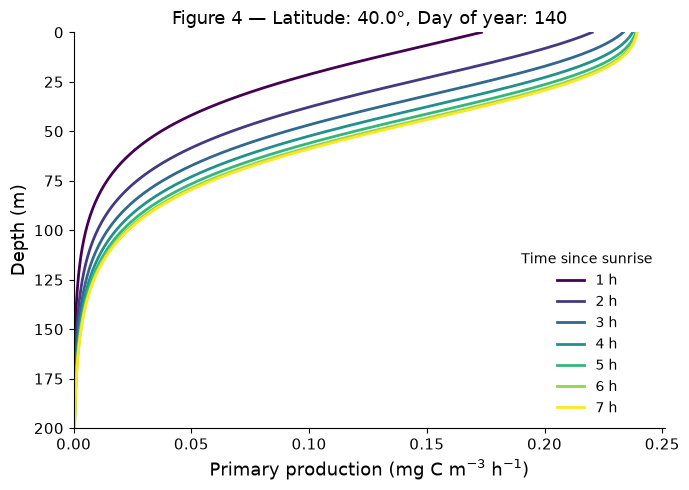

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Define parameters
# --------------------------------------------------

Latitude = 40.0
dayOfYear = 140
B = 0.04                 # Chlorophyll-a concentration (mg m^-3)

PB_M = 6.0               # Assimilation number
A_B = 0.02               # Initial slope

Tas = 0.98               # Air-sea transmittance
Tatm = 0.70              # Atmospheric transmission

MaxDepth = 200.0         # Maximum depth (m)

# --------------------------------------------------
# Calculate attenuation coefficient
# --------------------------------------------------

# Estimate Kd from chlorophyll-a using Morel relationship
logB = np.log10(B)

Kd = 4.6 / 10**(
    1.524
    - 0.436 * logB
    - 0.0145 * logB**2
    + 0.0186 * logB**3
)

# --------------------------------------------------
# Calculate daylength and irradiance
# --------------------------------------------------

# Daylength (seconds)
D = calculate_daylength(Latitude, dayOfYear)

# Daily integrated PAR (Einstein m^-2 d^-1)
PAR = calculate_PAR(Latitude, dayOfYear, Tatm)

# Convert PAR to micromoles
PAR = PAR * 1e6

# Maximum surface irradiance above and below water
Im_pl = np.pi * PAR / (2 * D)
Im_mn = Im_pl * Tas

# Time array and depth array (1 m resolution)
Time = np.linspace(0, D, 21)
Depth = np.arange(0, MaxDepth + 1, 1)

# Calculation of irradiance
I = (
    Im_mn
    * np.sin(np.pi * Time[:, None] / D)
    * np.exp(-Kd * Depth[None, :])
)

# --------------------------------------------------
# Calculate primary production
# --------------------------------------------------

# Saturation irradiance
I_k = PB_M / A_B

# Compute primary production at each time and depth
P_t_z = B * PB_M * (1 - np.exp(-I / I_k))

# Print calculated parameters
print(f'Latitude: {Latitude:.1f}° | Day of year: {dayOfYear}')
print(f'Daylength = {D / 3600:.1f} hours')
print(f'PAR = {PAR / 1e6:.1f} Einstein m⁻² d⁻¹')
print(f'Kd = {Kd:.3f} m⁻¹')
print(f'Maximum surface irradiance = {Im_mn:.1f} μmol m⁻² s⁻¹')
print(f'Maximum primary production = {np.max(P_t_z):.3f} mg C m⁻³ h⁻¹')


# --------------------------------------------------
# Figure 4: Primary production with depth and time
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 5))

# Select times hourly from 1 hour after sunrise until midday
PlotTimes = np.arange(1, np.floor(D / 7200) + 1)

# Generate colours from a continuous colormap
colors = plt.cm.viridis(np.linspace(0, 1, len(PlotTimes)))

for hour, color in zip(PlotTimes, colors):

    # Convert hours since sunrise to seconds
    t = hour * 3600

    # Calculate irradiance at each depth
    I_depth = (
        Im_mn
        * np.sin(np.pi * t / D)
        * np.exp(-Kd * Depth)
    )

    # Calculate primary production
    P_depth = B * PB_M * (1 - np.exp(-I_depth / I_k))

    ax.plot(
        P_depth,
        Depth,
        color=color,
        linewidth=2,
        label=f'{hour:g} h'
    )

# Axis labels
ax.set_xlabel(
    r'Primary production (mg C m$^{-3}$ h$^{-1}$)',
    fontsize=13
)
ax.set_ylabel('Depth (m)', fontsize=13)

# Axis limits (depth increasing downwards)
ax.set_xlim(0, None)
ax.set_ylim(MaxDepth, 0)

# Plot title
ax.set_title(
    f'Figure 4 — Latitude: {Latitude:.1f}°, Day of year: {dayOfYear}',
    fontsize=13
)

# Legend
ax.legend(
    title='Time since sunrise',
    frameon=False,
    fontsize=10,
    title_fontsize=10
)

# Remove top and right axes
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Format ticks
ax.tick_params(axis='both', direction='out', labelsize=11)

ax.grid(False)
plt.tight_layout()
plt.show()

Figure 4 shows output from running the code, from dawn to noon (note noon to dusk will give symmetric output for this modelling approach). As you can see, primary production changes as light changes over the course of the day, with highest primary production around noon.

**Question**: For some times of day, $P(z)$ looks like exponential decay. At other times of day, the relationship looks noticably different near the surface. Why is this? In what parts of the ocean might this relationship deviate most strongly from a simple exponential?

Have a play by varying input parameters (latitude, dayOfYear, PAR, B, PB_M, and AL_B), re-running the code and see how the graph changes. For guidance here are some realistic bounds to play with

- latitude (-70 to 70)
- dayOfYear (1 to 366)
- B (0.02 to 30.)
- PB_M (0.2 to 20)
- AL_B (0.006 to 0.1)

This will give you a feel for how variable primary production can be in the ocean. 

### Integrating primary production

Having produced a model that can compute primary production over a range of depths, and times of day, it is common to integrate the values over depth and daylength, to provide the value of primary production in units of mg C m$^{-2}$ d$^{-1}$. In such cases the primary production model is expressed as  

\begin{equation}
\begin{gathered}
P_{Z,T} = \int_0^D \int_0^{200\,\mathrm{m}}
B P^B_m \left[1 - \exp\left(-\frac{I(z,t)}{I_k}\right)\right]
\,\mathrm{d}z\,\mathrm{d}t,\\[6pt]
I(z,t) = I_m(0^+)T_{as} \sin\left(\frac{\pi t}{D}\right)
\exp\left(-K_d z\right),\\[6pt]
I_k = \frac{P^B_m}{\alpha^B}.
\end{gathered}
\end{equation}

Here we are integrating down to 200 m depth, which we consider to be an deepest limit for the photic depth. Rather than taking a fixed boundary like we have done, others use a variable boundary, such as the euphotic zone (1% light level), which changes with the optical properties of the water. No simple analytical solution exists for $P_{Z,T}$, so we will instead use numerical integration (the trapezium rule) to solve for $P_{Z,T}$.

To integrate the previous primary production simulations data, run the following lines of Python code.

Latitude: 20.0°
Annual mean daily primary production = 124.2 mg C m⁻² d⁻¹
Maximum daily primary production = 143.0 mg C m⁻² d⁻¹
Minimum daily primary production = 100.2 mg C m⁻² d⁻¹


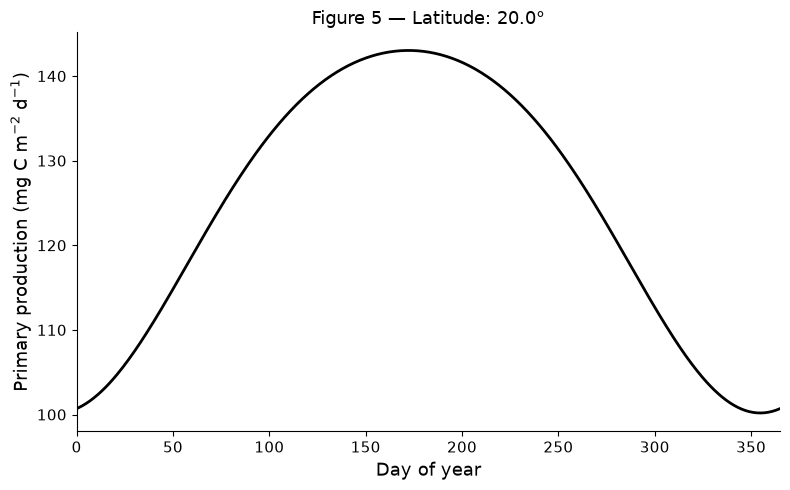

In [7]:
# --------------------------------------------------
# Figure 5: Seasonal variation in primary production
# --------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

# --------------------------------------------------
# Define parameters
# --------------------------------------------------

SelectedLatitude = 20.0  # Latitude (degrees N)

# Define day-of-year array
Days = np.arange(1, 366)

# Calculate daylength for each day (seconds)
D_days = calculate_daylength(SelectedLatitude, Days)

# Calculate daily PAR for each day (Einstein m^-2 d^-1)
PAR_days = calculate_PAR(SelectedLatitude, Days, Tatm)

# Convert PAR to micromoles
PAR_days = PAR_days * 1e6

# Maximum irradiance immediately below the surface
Im_days = np.pi * PAR_days * Tas / (2 * D_days)

# --------------------------------------------------
# Calculate primary production
# --------------------------------------------------

# Define normalised time over the daylight period
Time_fraction = np.linspace(0, 1, 101)

# Precompute time and depth attenuation factors
Time_factor = np.sin(np.pi * Time_fraction)
Depth_factor = np.exp(-Kd * Depth)

# Calculate irradiance for each day, time and depth
# Dimensions: day of year x time x depth
I_days = (
    Im_days[:, None, None]
    * Time_factor[None, :, None]
    * Depth_factor[None, None, :]
)

# Calculate primary production
P_days = B * PB_M * (1 - np.exp(-I_days / I_k))

# --------------------------------------------------
# Integrate over depth and time
# --------------------------------------------------

# Integrate over depth (mg C m^-2 h^-1)
P_depth = trapezoid(P_days, x=Depth, axis=2)

# Integrate over daylight time (mg C m^-2 d^-1)
P_int_days = (
    trapezoid(P_depth, x=Time_fraction, axis=1)
    * D_days / 3600
)

# --------------------------------------------------
# Print results
# --------------------------------------------------

print(f'Latitude: {SelectedLatitude:.1f}°')
print(f'Annual mean daily primary production = '
      f'{np.mean(P_int_days):.1f} mg C m⁻² d⁻¹')
print(f'Maximum daily primary production = '
      f'{np.max(P_int_days):.1f} mg C m⁻² d⁻¹')
print(f'Minimum daily primary production = '
      f'{np.min(P_int_days):.1f} mg C m⁻² d⁻¹')

# --------------------------------------------------
# Figure 5: Seasonal cycle of primary production
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

# Plot seasonal cycle
ax.plot(
    Days,
    P_int_days,
    color='black',
    linewidth=2
)

# Axis labels
ax.set_xlabel('Day of year', fontsize=13)
ax.set_ylabel(
    r'Primary production (mg C m$^{-2}$ d$^{-1}$)',
    fontsize=13
)

# Axis limits
ax.set_xlim(1, 365)
ax.set_xticks(np.arange(0, 366, 50))

# Plot title
ax.set_title(
    f'Figure 5 — Latitude: {SelectedLatitude:.1f}°',
    fontsize=13
)

# Remove top and right axes
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Format ticks
ax.tick_params(axis='both', direction='out', labelsize=11)

ax.grid(False)
plt.tight_layout()
plt.show()

Plot $P_{Z,T}$ curves for different latitudes.

**Question:** Are these curves similar to what you'd expect from actual seasonal primary production variability? Why or why not?

We now have all the components in place to compute daily integrated primary production at a satellite pixel, based on PAR and chlorophyll-a ($B$) input. 

Further integrations can be conducted in time and space, for example, application of primary production models at global scale suggest phytoplankton produce around 50 Gt C y$^{-1}$ (Kulk et al. 2020). This computation involves integrating further in space (over the global ocean) and time (over the annual cycle).  

## Changes in primary production over the season

One of the advantages of satellite remote sensing, is the temporal acquisition of data over the full seasonal cycle. 

Here we illustrate the application of our primary production model to a time-series of satellite data, extracted from weekly composites (8-day averages) of $B$ and PAR at a location in the North Atlantic. 

Run the following lines of Python code.

Latitude: 50.0°
Depth integrated = 0–200 m
Annual mean daily primary production = 372.3 mg C m⁻² d⁻¹
Maximum daily primary production = 1341.5 mg C m⁻² d⁻¹
Minimum daily primary production = 42.5 mg C m⁻² d⁻¹


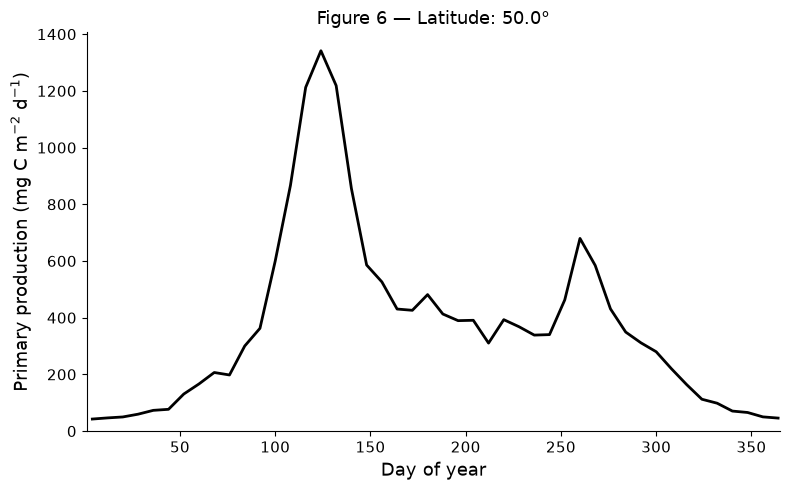

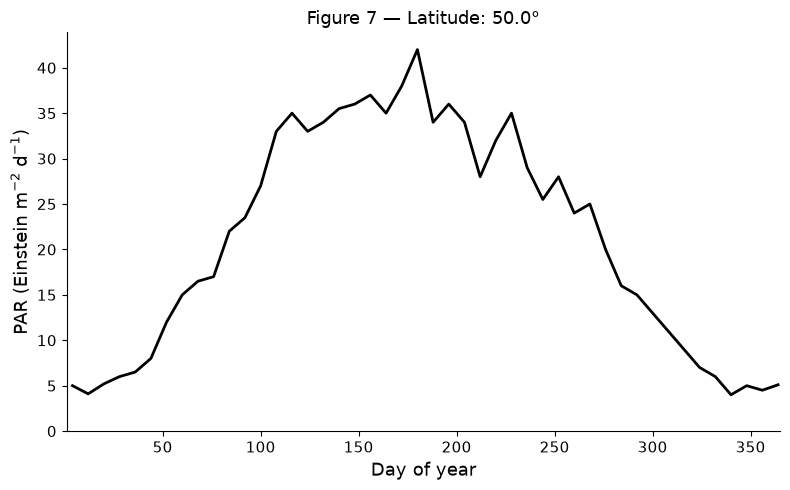

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

# --------------------------------------------------
# Define parameters
# --------------------------------------------------

Latitude = 50.0
PB_M = 6.0               # Assimilation number
A_B = 0.02               # Initial slope
Tas = 0.98               # Air-sea transmittance

MaxDepth = 200.0         # Maximum depth (m)

# --------------------------------------------------
# Satellite time series (MODIS-Aqua example)
# --------------------------------------------------

# Day of year (midpoints of 8-day periods)
dayOfYear_MAT = (np.arange(46) + 1) * 8.0 - 4.0

# Chlorophyll-a concentration (mg m^-3)
B_MAT = np.array([
    0.10, 0.15, 0.12, 0.13, 0.16, 0.13,
    0.18, 0.20, 0.25, 0.22, 0.32, 0.40,
    0.80, 1.20, 2.00, 2.50, 2.00, 1.00,
    0.50, 0.40, 0.30, 0.27, 0.30, 0.29,
    0.25, 0.27, 0.23, 0.30, 0.25, 0.27,
    0.32, 0.50, 1.20, 0.90, 0.70, 0.65,
    0.59, 0.60, 0.50, 0.40, 0.30, 0.30,
    0.31, 0.20, 0.15, 0.11
])

# Daily integrated PAR (Einstein m^-2 d^-1)
PAR_MAT = np.array([
     5.0,  4.1,  5.2,  6.0,  6.5,  8.0,
    12.0, 15.0, 16.5, 17.0, 22.0, 23.5,
    27.0, 33.0, 35.0, 33.0, 34.0, 35.5,
    36.0, 37.0, 35.0, 38.0, 42.0, 34.0,
    36.0, 34.0, 28.0, 32.0, 35.0, 29.0,
    25.5, 28.0, 24.0, 25.0, 20.0, 16.0,
    15.0, 13.0, 11.0,  9.0,  7.0,  6.0,
     4.0,  5.0,  4.5,  5.1
])

# --------------------------------------------------
# Calculate attenuation and daylength
# --------------------------------------------------

# Estimate Kd from chlorophyll-a using Morel relationship
logB = np.log10(B_MAT)

Kd_MAT = 4.6 / 10**(
    1.524
    - 0.436 * logB
    - 0.0145 * logB**2
    + 0.0186 * logB**3
)

# Daylength for each satellite observation (seconds)
D_MAT = calculate_daylength(Latitude, dayOfYear_MAT)

# Convert PAR to micromoles
PAR_umol = PAR_MAT * 1e6

# Maximum irradiance immediately below the sea surface
Im_MAT = np.pi * PAR_umol * Tas / (2 * D_MAT)

# --------------------------------------------------
# Calculate primary production
# --------------------------------------------------

# Saturation irradiance
I_k = PB_M / A_B

# Normalised time and depth arrays
Time_fraction = np.linspace(0, 1, 101)
Depth = np.arange(0, MaxDepth + 1, 1)

# Calculate irradiance at each time and depth
# Dimensions: observation x time x depth
I_MAT = (
    Im_MAT[:, None, None]
    * np.sin(np.pi * Time_fraction[None, :, None])
    * np.exp(-Kd_MAT[:, None, None] * Depth[None, None, :])
)

# Calculate primary production
P_MAT = (
    B_MAT[:, None, None]
    * PB_M
    * (1 - np.exp(-I_MAT / I_k))
)

# --------------------------------------------------
# Integrate primary production over depth and time
# --------------------------------------------------

# Integrate over depth (mg C m^-2 h^-1)
P_int_z = trapezoid(P_MAT, x=Depth, axis=2)

# Integrate over normalised daylight time
# Multiply by daylength in hours to obtain mg C m^-2 d^-1
P_int = (
    trapezoid(P_int_z, x=Time_fraction, axis=1)
    * D_MAT / 3600
)

# Set invalid observations to NaN
valid = (B_MAT > 0) & (PAR_MAT > 0)
P_int = np.where(valid, P_int, np.nan)

# --------------------------------------------------
# Print results
# --------------------------------------------------

print(f'Latitude: {Latitude:.1f}°')
print(f'Depth integrated = 0–{MaxDepth:.0f} m')
print(f'Annual mean daily primary production = {np.nanmean(P_int):.1f} mg C m⁻² d⁻¹')
print(f'Maximum daily primary production = {np.nanmax(P_int):.1f} mg C m⁻² d⁻¹')
print(f'Minimum daily primary production = {np.nanmin(P_int):.1f} mg C m⁻² d⁻¹')

# --------------------------------------------------
# Figure 6: Seasonal cycle of primary production
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    dayOfYear_MAT,
    P_int,
    color='black',
    linewidth=2
)

# Axis labels
ax.set_xlabel('Day of year', fontsize=13)
ax.set_ylabel(
    r'Primary production (mg C m$^{-2}$ d$^{-1}$)',
    fontsize=13
)

# Axis limits
ax.set_xlim(1, 365)
ax.set_ylim(0, None)

# Plot title
ax.set_title(
    f'Figure 6 — Latitude: {Latitude:.1f}°',
    fontsize=13
)

# Remove top and right axes
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Format ticks
ax.tick_params(axis='both', direction='out', labelsize=11)

ax.grid(False)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# Figure 7: Seasonal cycle of satellite PAR
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    dayOfYear_MAT,
    PAR_MAT,
    color='black',
    linewidth=2
)

# Axis labels
ax.set_xlabel('Day of year', fontsize=13)
ax.set_ylabel(
    r'PAR (Einstein m$^{-2}$ d$^{-1}$)',
    fontsize=13
)

# Axis limits
ax.set_xlim(1, 365)
ax.set_ylim(0, None)

# Plot title
ax.set_title(
    f'Figure 7 — Latitude: {Latitude:.1f}°',
    fontsize=13
)

# Remove top and right axes
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Format ticks
ax.tick_params(axis='both', direction='out', labelsize=11)

ax.grid(False)
plt.tight_layout()
plt.show()

Figure 6 shows the output from running the primary production model on a time-series of satellite data in the North Atlantic. This time-series is characteristic of subpolar regions. 

**Question:** Given what you know about this region, explain the seasonality you see in Figure 6 and 7.

## Primary production from a satellite image

Now we have our primary production model working, we are going to plot primary production around the southwest of the UK, on the 4th June 2023 using a MODIS-Aqua satellite image. To do this we have downloaded a global (9 km resolution) composite image of 4th June 2023 (day 155 of 2023) of chlorophyll-a ($B$) and PAR from the MODIS Aqua sensor. For this practical, these images have already been downloaded and added to the repository. However, if are interested in learning how to download satellite images, here are a few steps on doing it

- First, you need to register on the Earthdata login (https://urs.earthdata.nasa.gov/users/new) to gain access to the data. Keep your username and password.
- The data used in the practical is located on the NASA website https://oceandata.sci.gsfc.nasa.gov/
- The specific chlorophyll-a ($B$) image we use can be found by clicking on the following link to the NASA website https://oceancolor.gsfc.nasa.gov/l3/ and searching for the data on 4th June 2023". If you are logged in, the image should download automatically, if not you may be redirected to the login-page, type in your details and it should download. This image is a global mapped image of chlorophyll-a ($B$).
- The specific PAR image we use can be found by following the same link and changiung the product to PAR it is called"AQUA_MODIS.20230604.L3m.DAY.PAR.par.9km.NRT.nc". This image is a global mapped image of PAR at the same resolution.

In this practical, we have already downloaded the image automatically and put it in the repository where this Juypter notebook is hosted, and so can call the image directly.

We are now going to read these images into Python, extract data for the region of interest, run our primary production model, and plot a map of primary production. 
	
Run the following lines of Python code. This may take a few minutes to run.

Date: 04 June 2023 | Day of year: 155
Region: 47.0–52.0°N, -10.0–-3.0°E
Depth integrated = 0–200 m
Valid satellite pixels = 4363
Mean primary production = 1027.1 mg C m⁻² d⁻¹
Standard deviation = 1273.2 mg C m⁻² d⁻¹


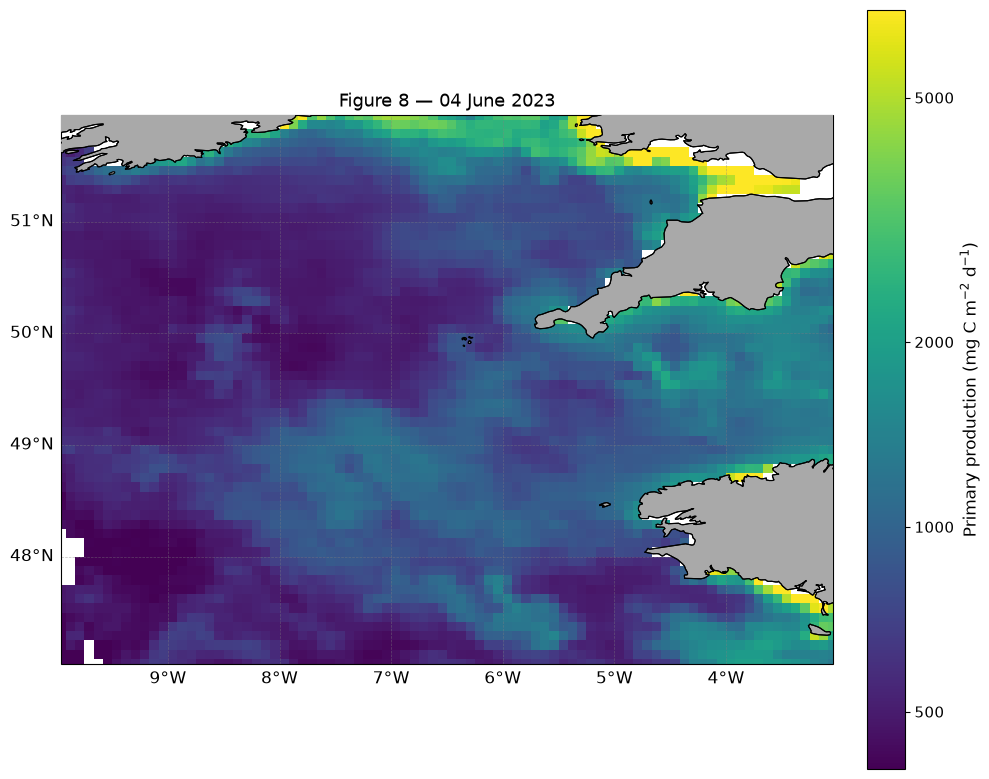

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from netCDF4 import Dataset
from scipy.integrate import trapezoid
from matplotlib.colors import LogNorm
from matplotlib.ticker import LogLocator, ScalarFormatter
from datetime import datetime

# --------------------------------------------------
# Define parameters
# --------------------------------------------------

PB_M = 6.0               # Assimilation number
A_B = 0.02               # Initial slope
Tas = 0.98               # Air-sea transmittance

MaxDepth = 200.0         # Maximum depth (m)
Vertical_res = 5.0       # Vertical integration resolution (m)
Temporal_res = 30.0      # Temporal integration resolution (minutes)

# Region of interest
Min_lon = -10.0
Max_lon = -3.0
Min_lat = 47.0
Max_lat = 52.0

# --------------------------------------------------
# Read MODIS-Aqua satellite data
# --------------------------------------------------

# Chlorophyll-a concentration (mg m^-3)
CHL_DATA = '../data/AQUA_MODIS/AQUA_MODIS.20230604.L3m.DAY.CHL.chlor_a.9km.NRT.nc'

with Dataset(CHL_DATA, 'r') as fh:

    lon = fh.variables['lon'][:]
    lat = fh.variables['lat'][:]
    B_MAT = fh.variables['chlor_a'][:]

    # Extract observation date from product name
    product_name = fh.getncattr('product_name')
    date_string = product_name.split('.')[1]

    # Convert to datetime and calculate day of year
    observation_date = datetime.strptime(date_string, '%Y%m%d')
    dayOfYear = observation_date.timetuple().tm_yday

# Daily integrated PAR (Einstein m^-2 d^-1)
PAR_DATA = '../data/AQUA_MODIS/AQUA_MODIS.20230604.L3m.DAY.PAR.par.9km.NRT.nc'

with Dataset(PAR_DATA, 'r') as fh:
    PAR_MAT = fh.variables['par'][:]

# --------------------------------------------------
# Extract region of interest
# --------------------------------------------------

# Identify latitude and longitude indices
lat_idx = np.where((lat > Min_lat) & (lat < Max_lat))[0]
lon_idx = np.where((lon > Min_lon) & (lon < Max_lon))[0]

# Extract satellite data
B_MAT = B_MAT[np.ix_(lat_idx, lon_idx)]
PAR_MAT = PAR_MAT[np.ix_(lat_idx, lon_idx)]

lat = lat[lat_idx]
lon = lon[lon_idx]

# Convert masked values to NaN
B_MAT = np.ma.filled(B_MAT.astype(float), np.nan)
PAR_MAT = np.ma.filled(PAR_MAT.astype(float), np.nan)

# Identify valid satellite observations
valid = (
    np.isfinite(B_MAT)
    & np.isfinite(PAR_MAT)
    & (B_MAT > 0)
    & (PAR_MAT > 0)
)

# --------------------------------------------------
# Calculate attenuation coefficient
# --------------------------------------------------

# Estimate Kd from chlorophyll-a using Morel relationship
logB = np.log10(np.where(valid, B_MAT, np.nan))

Kd_MAT = 4.6 / 10**(
    1.524
    - 0.436 * logB
    - 0.0145 * logB**2
    + 0.0186 * logB**3
)

# --------------------------------------------------
# Calculate daylength and surface irradiance
# --------------------------------------------------

# Daylength at each latitude (seconds)
D_lat = calculate_daylength(lat, dayOfYear)

# Expand daylength to match satellite grid
D_MAT = D_lat[:, None]

# Convert PAR to micromoles
PAR_umol = PAR_MAT * 1e6

# Maximum irradiance immediately below the surface
Im_MAT = np.pi * PAR_umol * Tas / (2 * D_MAT)

# Saturation irradiance
I_k = PB_M / A_B

# --------------------------------------------------
# Calculate daily integrated primary production
# --------------------------------------------------

# Number of time intervals based on maximum daylength
N_time = max(
    1,
    int(np.ceil(np.max(D_lat) / (Temporal_res * 60)))
)

# Normalised daylight time (sunrise = 0, sunset = 1)
Time_fraction = np.linspace(0, 1, N_time + 1)

# Depth array at specified resolution
Depth = np.arange(
    0, MaxDepth + Vertical_res, Vertical_res
)

# Precompute temporal attenuation
Time_factor = np.sin(np.pi * Time_fraction)

# Allocate output array
P_int = np.full(B_MAT.shape, np.nan)

# Process image in small latitude batches
BatchSize = 5

for start in range(0, len(lat), BatchSize):

    end = min(start + BatchSize, len(lat))

    # Extract batch
    B_batch = B_MAT[start:end, :]
    Kd_batch = Kd_MAT[start:end, :]
    Im_batch = Im_MAT[start:end, :]
    D_batch = D_lat[start:end]

    # Identify valid pixels
    valid_batch = valid[start:end, :]

    # Retain valid pixels
    B_valid = B_batch[valid_batch]
    Kd_valid = Kd_batch[valid_batch]
    Im_valid = Im_batch[valid_batch]

    if len(B_valid) == 0:
        continue

    # Irradiance at each time and depth
    # Dimensions: pixel x time x depth
    I_batch = (
        Im_valid[:, None, None]
        * Time_factor[None, :, None]
        * np.exp(
            -Kd_valid[:, None, None]
            * Depth[None, None, :]
        )
    )

    # Calculate primary production
    P_batch = (
        B_valid[:, None, None]
        * PB_M
        * (1 - np.exp(-I_batch / I_k))
    )

    # Integrate over depth (mg C m^-2 h^-1)
    P_depth = trapezoid(
        P_batch,
        x=Depth,
        axis=2
    )

    # Integrate over normalised daylight time
    P_daily = trapezoid(
        P_depth,
        x=Time_fraction,
        axis=1
    )

    # Convert normalised time to daylight hours
    D_valid = np.broadcast_to(
        D_batch[:, None],
        B_batch.shape
    )[valid_batch]

    P_daily = P_daily * D_valid / 3600

    # Store results
    P_int[start:end, :][valid_batch] = P_daily

# --------------------------------------------------
# Print results
# --------------------------------------------------

print(f'Date: {observation_date:%d %B %Y} | Day of year: {dayOfYear}')
print(f'Region: {Min_lat:.1f}–{Max_lat:.1f}°N, '
      f'{Min_lon:.1f}–{Max_lon:.1f}°E')
print(f'Depth integrated = 0–{MaxDepth:.0f} m')
print(f'Valid satellite pixels = {np.sum(valid)}')
print(f'Mean primary production = {np.nanmean(P_int):.1f} mg C m⁻² d⁻¹')
print(f'Standard deviation = {np.nanstd(P_int):.1f} mg C m⁻² d⁻¹')

# --------------------------------------------------
# Figure 8: Spatial distribution of primary production
# --------------------------------------------------

# Original figure dimensions and projection
fig = plt.figure(figsize=(10, 14))

ax = fig.add_subplot(
    111,
    projection=ccrs.PlateCarree(central_longitude=-5)
)

# --------------------------------------------------
# Automatic logarithmic colour scaling (1st–99th percentiles)
# --------------------------------------------------

# Mask invalid and non-positive values
P_plot = np.ma.masked_less_equal(
    np.ma.masked_invalid(P_int), 0
)

# Calculate percentile limits
Min_P, Max_P = np.percentile(
    P_plot.compressed(), [1, 99]
)

# Plot primary production using pcolormesh
mesh = ax.pcolormesh(
    lon,
    lat,
    P_plot,
    norm=LogNorm(vmin=Min_P, vmax=Max_P, clip=True),
    cmap='viridis',
    shading='auto',
    transform=ccrs.PlateCarree(),
    rasterized=True
)

# --------------------------------------------------
# Add land and coastlines
# --------------------------------------------------

ax.add_feature(
    cfeature.LAND,
    facecolor='darkgray',
    edgecolor='black',
    linewidth=0.8,
    zorder=3
)

ax.coastlines(
    resolution='10m',
    linewidth=0.8,
    color='black',
    zorder=4
)

# --------------------------------------------------
# Restore original geographical extent
# --------------------------------------------------

ax.set_extent(
    [
        np.min(lon),
        np.max(lon),
        np.min(lat),
        np.max(lat)
    ],
    crs=ccrs.PlateCarree()
)

# --------------------------------------------------
# Add geographical gridlines and labels
# --------------------------------------------------

gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
)

gl.top_labels = False
gl.bottom_labels = True
gl.left_labels = True
gl.right_labels = False

gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}

# Plot title using automatically extracted date
ax.set_title(
    f'Figure 8 — {observation_date:%d %B %Y}',
    fontsize=13
)

# --------------------------------------------------
# Colour bar with rounded logarithmic tick values
# --------------------------------------------------

# Candidate ticks at 1, 2 and 5 times powers of ten
tick_locator = LogLocator(base=10, subs=(1, 2, 5))

ticks = tick_locator.tick_values(Min_P, Max_P)

# Retain only ticks within the percentile range
ticks = ticks[(ticks >= Min_P) & (ticks <= Max_P)]

# Create colour bar
cbar = fig.colorbar(
    mesh,
    ax=ax,
    orientation='vertical',
    fraction=0.045,
    pad=0.04,
    shrink=0.85,
    ticks=ticks
)

# Display ordinary numbers rather than scientific notation
cbar.ax.yaxis.set_major_formatter(ScalarFormatter())
cbar.ax.minorticks_off()

cbar.set_label(
    r'Primary production (mg C m$^{-2}$ d$^{-1}$)',
    fontsize=12
)

cbar.ax.tick_params(labelsize=11)

plt.tight_layout()
plt.show()

Having run the code, Figure 8 shows a map of primary production for the 4th June 2023 around the south-west UK, Ireland and northern France. Land is shown in white and missing data (e.g. from clouds) are shown in white (note the resolution of the data is quite course, 9 km). High primary production is observed around the coastlines of Plymouth and northern France. We also can see a bloom off the coastline of Plymouth in the English Channel.

**Question:** Given the horizontal spatial resolution of the data $\Delta x$, vertical resolution used for depth integration $\Delta z$, and temporal resolution used for time integration $\Delta t$, how does the computational cost (number of calculations required) for computing primary production for a given area scale with $\Delta x$, $\Delta z$, and $\Delta t$? How sensitive are the computed values of $P_{Z,T}$ on $\Delta x$ and $\Delta t$?

**Question:** For this environment, considering the assumptions that have gone into our model (e.g. assuming that Chl-a is a proxy for $K_d$, depth-independent $B$, etc.), how appropriate do you think our model is for computing $P_{Z,T}$ is? If you wanted to improve this model, what changes would you prioritise?

**Question:** For the suggested changes above, how would you test whether they have improved the performance of the model?



## Further work

Having completed the practical, here are some additional tasks you may want to do in your own time.

- Try plotting different regions of the ocean by changing the bounds "Max_lon", "Min_lon", "Max_lat" and "Min_lat". Note however, the bigger the area, the longer the code will take to run (a complete global image will take a very long time to run). An example that works well on the above image (4th June 2023) is Max_lon = 16.0,  Min_lon = 12.0, Max_lat = -22.0,  Min_lat = -26.0, off the coastline of Namibia.
- Try varying model parameters (PB_M and AL_B) and see what results you get. The assumption here is that these parameters are static. There are ways we try and estimate the parameters dynamically from space too, to account for the variability (see for instance Saux-Picart et al. 2014). Ultimately, it would be good to integrate these functions into the code.


## Conclusion

In this practical you have learnt how to estimate primary production in the ocean using an available-light model of photosynthesis. You have used satellite ocean colour data (specifically the chlorophyll-a concentration and photosynthetically available radiation) to map primary production in time (over a seasonal cycle at a specific location) and in space (around the south-west UK). The model is a fairly simple one, and it is important to acknowledge the assumptions in the model when analysing data output. 

You should now have a better understanding of what controls primary production and how to estimate primary production using satellite data.

## References:

Kulk, G., Platt, T., Dingle, J., Jackson, T., Jönsson, B.F., Bouman, H.A., Babin, M., Brewin, R.J., Doblin, M., Estrada, M. & Figueiras, F.G. (2020). Primary Production, an Index of Climate Change in the Ocean: Satellite-Based Estimates over Two Decades. Remote Sensing, 12(5), 826. https://doi.org/10.3390/rs12050826

Morel, A., Huot, Y., Gentili, B., Werdell, P.J., Hooker, S.B. & Franz, B.A. (2007). Examining the consistency of products derived from various ocean color sensors in open ocean (Case 1) waters in the perspective of a multi-sensor approach. Remote Sensing of Environment, 111(1), 69-88. https://doi.org/10.1016/j.rse.2007.03.012

Platt, T., Gallegos, C.L. & Harrison, W.G. (1980) Photoinhibition of photosynthesis in natural assemblages of marine phytoplankton. J. Mar. Res., 38, 687-701 https://images.peabody.yale.edu/publications/jmr/jmr38-04-06.pdf

Picart, S.S., Sathyendranath, S., Dowell, M., Moore, T. and Platt, T. (2014). Remote sensing of assimilation number for marine phytoplankton. Remote Sensing of Environment, 146, 87-96. https://www.sciencedirect.com/science/article/pii/S0034425713004136